In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Bank_Churn.csv')

In [4]:
df.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15571816,Ritchie,850,Spain,Female,70,5,0.00,1,1,1,705.18,0
1,15653521,Onuora,850,Germany,Female,40,7,104449.80,1,1,1,747.88,0
2,15657603,Finch,850,France,Female,35,6,81684.97,1,1,0,824.00,0
3,15676571,Bezrukova,850,France,Male,55,6,0.00,1,1,0,944.41,1
4,15644699,Crawford,850,France,Female,40,0,0.00,2,1,0,1099.95,0


In [6]:
df.shape

(10000, 13)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1015.8+ KB


In [9]:
df.isnull().sum()

CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [12]:
df.drop(columns=['CustomerId','Surname'],inplace=True) 

In [13]:
df.dtypes

CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [14]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [15]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [16]:
df.to_csv("Bank_Churn_Cleaned.csv",index=False)

In [17]:
# Exploratory Data Analysis (EDA) using Python

total_customers = len(df)

churned_customers = df["Exited"].sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 10000
Churned Customers: 2037
Churn Rate: 20.37 %


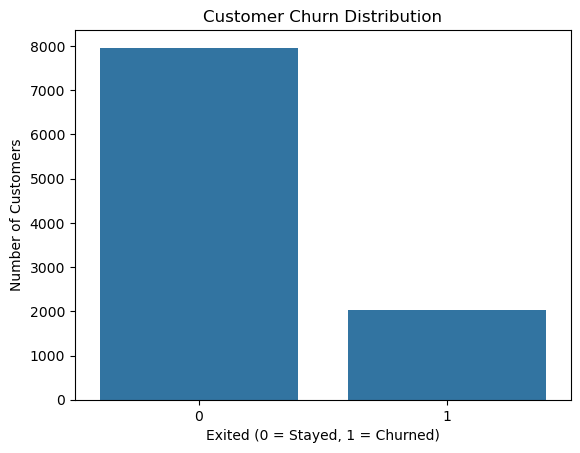

In [18]:
# Visualize churn distribution

sns.countplot(data=df, x="Exited")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

In [21]:
# Analyze churn by geography

geo_churn = df.groupby("Geography")["Exited"].mean() * 100

print(geo_churn)a

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64


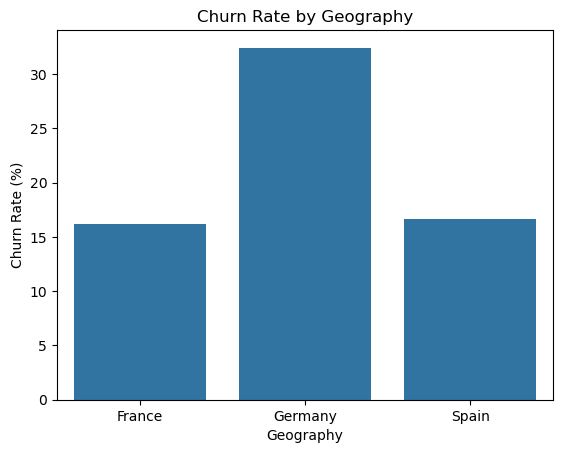

In [23]:
sns.barplot(x=geo_churn.index, y=geo_churn.values)

plt.title("Churn Rate by Geography")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Geography")

plt.show()

In [22]:
# Analyze churn by Gender

gender_churn = df.groupby("Gender")["Exited"].mean() * 100
print(gender_churn)

Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


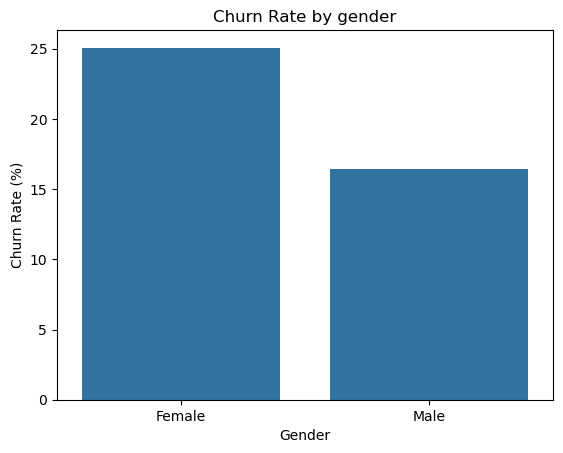

In [24]:
sns.barplot(x=gender_churn.index, y=gender_churn.values)

plt.title("Churn Rate by gender")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Gender")

plt.show()

In [25]:
#Analyze Churn by Age

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[18, 30, 40, 50, 60, 100],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest=True
)

In [27]:
age_churn = df.groupby("AgeGroup", observed=False)["Exited"].mean() * 100

print(age_churn)

AgeGroup
18-30     7.520325
31-40    12.087171
41-50    33.965517
51-60    56.210790
60+      24.784483
Name: Exited, dtype: float64


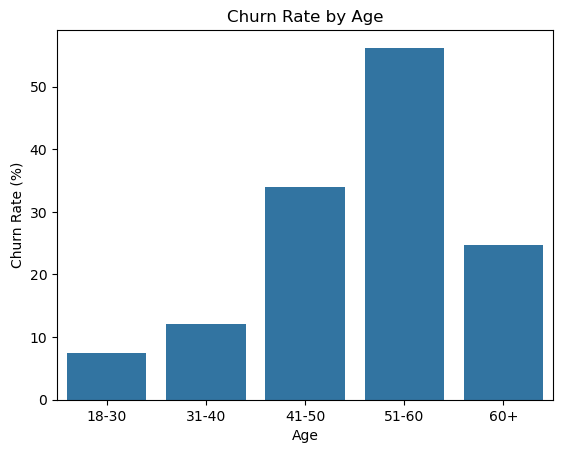

In [28]:
sns.barplot(x=age_churn.index, y=age_churn.values)

plt.title("Churn Rate by Age")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Age")

plt.show()

In [29]:
# Analyze Churn by Tenure

tenure_churn = df.groupby("Tenure")["Exited"].mean() * 100

print(tenure_churn)

Tenure
0     23.002421
1     22.415459
2     19.179389
3     21.110010
4     20.525784
5     20.652174
6     20.268873
7     17.217899
8     19.219512
9     21.646341
10    20.612245
Name: Exited, dtype: float64


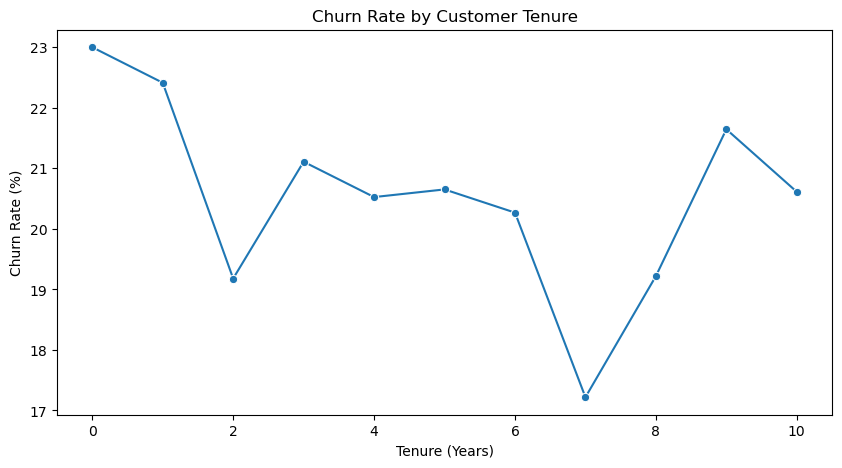

In [30]:
plt.figure(figsize=(10, 5))

sns.lineplot(x=tenure_churn.index, y=tenure_churn.values, marker="o")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Churn Rate (%)")

plt.show()

In [31]:
# Analyze churn by active membership

active_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

print(active_churn)

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


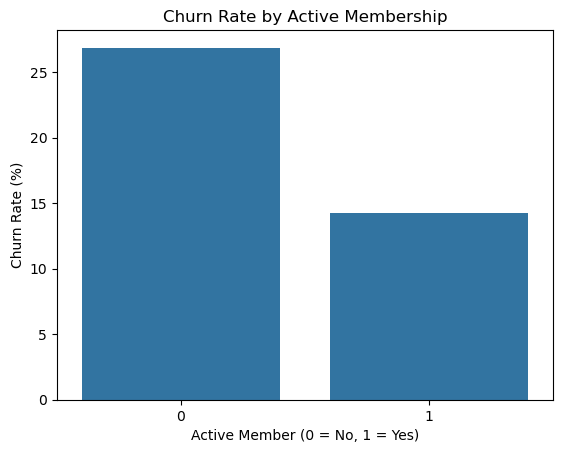

In [32]:
sns.barplot(x=active_churn.index, y=active_churn.values)

plt.title("Churn Rate by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.show()

In [33]:
# Analyze churn by number of products

product_churn = df.groupby("NumOfProducts")["Exited"].mean() * 100

print(product_churn)

NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64


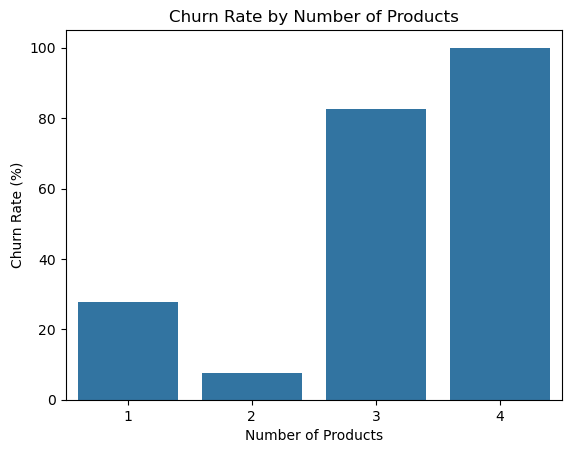

In [34]:
sns.barplot(x=product_churn.index, y=product_churn.values)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.show()

In [36]:
# Analyze churn by account balance

df["BalanceGroup"] = pd.cut(
    df["Balance"],
    bins=[-1, 50000, 100000, 150000, 300000],
    labels=["0-50K", "50K-100K", "100K-150K", "150K+"]
)

balance_churn = df.groupby("BalanceGroup", observed=False)["Exited"].mean() * 100

print(balance_churn)

BalanceGroup
0-50K        14.247021
50K-100K     19.880716
100K-150K    25.770235
150K+        23.116615
Name: Exited, dtype: float64


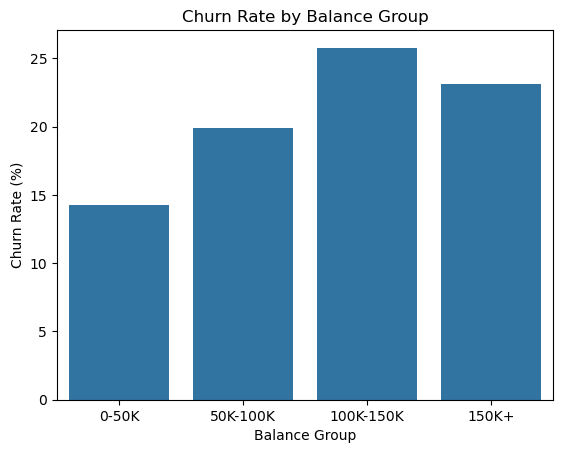

In [37]:
sns.barplot(x=balance_churn.index, y=balance_churn.values)

plt.title("Churn Rate by Balance Group")
plt.xlabel("Balance Group")
plt.ylabel("Churn Rate (%)")

plt.show()

In [38]:
# Analyze churn by credit score

df["CreditScoreGroup"] = pd.cut(
    df["CreditScore"],
    bins=[0, 580, 670, 740, 800, 900],
    labels=["Poor", "Fair", "Good", "Very Good", "Excellent"]
)

credit_churn = df.groupby("CreditScoreGroup", observed=False)["Exited"].mean() * 100

print(credit_churn)

CreditScoreGroup
Poor         22.147931
Fair         20.388060
Good         18.815186
Very Good    20.246914
Excellent    19.689922
Name: Exited, dtype: float64


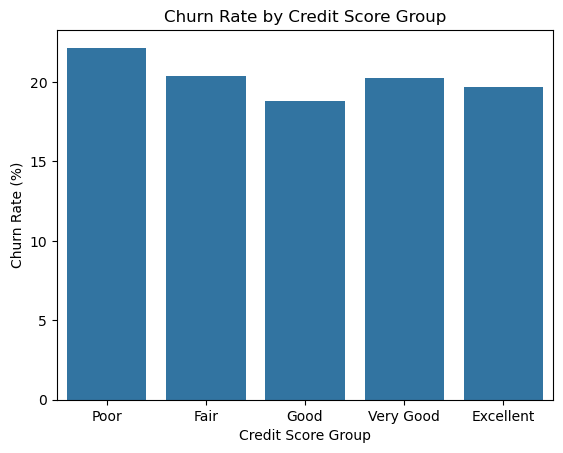

In [39]:
sns.barplot(x=credit_churn.index, y=credit_churn.values)

plt.title("Churn Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Churn Rate (%)")

plt.show()

In [ ]:
'''
Which geography has the highest churn?
- Germany has the highest churn rate (32.443204).

Which age group has the highest churn?
- 51-60 age group has highest churn.

Are inactive customers more likely to leave?
- Yes 

Which tenure groups show higher churn?
- Groups with 0 Tenure show higher churn.

What is the overall churn rate?
- The overall Churn Rate: 20.37 %

What could the bank do to improve retention?
- Based on the customer churn analysis, the bank should prioritize retention strategies for customer segments with comparatively high churn rates. 
  Potential interventions include targeted engagement campaigns for inactive customers, personalized banking services for high-risk age groups,
  and proactive customer support for segments exhibiting elevated churn. The bank should continuously monitor churn-related KPIs to assess the 
  effectiveness of these interventions.


'''